# Proyek Analisis Data: Air Quality Dataset (PRSA Data Beijing, 12 Stasiun)
- **Nama:** [Input Nama]
- **Email:** [Input Email]
- **ID Dicoding:** [Input Username]

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

**Konteks bisnis (asumsi):** stakeholder adalah dinas lingkungan hidup / pemerintah kota Beijing yang perlu menentukan *kapan*, *di mana*, dan *dalam kondisi cuaca apa* intervensi pengendalian polusi udara serta peringatan dini paling dibutuhkan. Dataset yang digunakan adalah **PRSA Beijing Multi-Site Air Quality**: data per jam dari 12 stasiun pemantau, **1 Maret 2013 – 28 Februari 2017**. Fokus analisis adalah **PM2.5** (partikel halus berdiameter ≤ 2,5 µm), polutan dengan dampak kesehatan terbesar. Baku mutu acuan: **75 µg/m³** (rata-rata 24 jam, Kelas II GB 3095-2012, China) dan **35 µg/m³** (rata-rata tahunan, Kelas II).

- **Pertanyaan 1:** Berapa rata-rata konsentrasi PM2.5 (µg/m³) dari 12 stasiun pemantau Beijing pada setiap periode 12 bulan (Maret–Februari) dan setiap musim selama Maret 2013 – Februari 2017, serta pada musim apa konsentrasinya paling tinggi dan paling rendah?
- **Pertanyaan 2:** Stasiun mana yang memiliki persentase hari dengan rata-rata PM2.5 harian di atas 75 µg/m³ paling tinggi dan paling rendah selama Maret 2013 – Februari 2017, dan berapa selisih persentasenya antara kelompok stasiun perkotaan dan stasiun pinggiran kota?
- **Pertanyaan 3:** Pada kombinasi arah dan kecepatan angin berapa rata-rata PM2.5 paling tinggi selama Maret 2013 – Februari 2017, dan berapa persen penurunan PM2.5 ketika kecepatan angin > 3 m/s dibandingkan ≤ 1 m/s?

| Pertanyaan | Specific | Measurable | Action-Oriented | Relevant | Time-bound |
|---|---|---|---|---|---|
| 1 | PM2.5 per periode 12 bulan & musim, 12 stasiun | rata-rata µg/m³ | menentukan musim prioritas intervensi & kampanye | sesuai tujuan: kapan intervensi dibutuhkan | Mar 2013 – Feb 2017 |
| 2 | persentase hari melewati 75 µg/m³ per stasiun, perkotaan vs pinggiran | % hari & selisih poin persentase | menentukan wilayah prioritas | sesuai tujuan: di mana intervensi dibutuhkan | Mar 2013 – Feb 2017 |
| 3 | PM2.5 menurut arah × kecepatan angin | rata-rata µg/m³ & % penurunan | menyusun aturan peringatan dini berbasis cuaca | sesuai tujuan: dalam kondisi apa peringatan dikeluarkan | Mar 2013 – Feb 2017 |

## Import Semua Packages/Library yang Digunakan

In [1]:
import glob
import os

import numpy as np
import pandas as pd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch

pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

# Palet warna konsisten untuk seluruh visualisasi
C_BLUE, C_ORANGE = '#2a78d6', '#eb6834'      # kategorikal: perkotaan = biru, pinggiran = oranye
INK, INK2, GRID = '#0b0b0b', '#52514e', '#e4e3df'
SEQ = LinearSegmentedColormap.from_list(     # sekuensial satu warna (biru) untuk magnitudo
    'seq_blue', ['#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])

plt.rcParams.update({
    'figure.dpi': 100, 'font.size': 10, 'text.color': INK,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#b9b8b2', 'axes.labelcolor': INK2,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.grid': True, 'axes.axisbelow': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'xtick.color': INK2, 'ytick.color': INK2, 'legend.frameon': False,
})
SUMBER = 'Sumber: PRSA Beijing Multi-Site Air Quality, 12 stasiun, Mar 2013 – Feb 2017'

## Data Wrangling

### Gathering Data

#### Load df air quality (12 stasiun)

In [2]:
# Berkas dicari di folder 'data/'; jika tidak ada (mis. file diunggah langsung ke Colab), dicari di folder kerja.
DATA_DIR = 'data' if os.path.isdir('data') else '.'
files = sorted(glob.glob(os.path.join(DATA_DIR, 'PRSA_Data_*.csv')))
assert files, "Berkas PRSA_Data_*.csv tidak ditemukan. Letakkan ke-12 CSV di folder 'data/' atau di folder yang sama dengan notebook."
print(f'Jumlah berkas stasiun: {len(files)}')
for f in files:
    print(' -', os.path.basename(f))

raw_df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
print('\nUkuran data gabungan (baris, kolom):', raw_df.shape)
raw_df.head()

Jumlah berkas stasiun: 12
 - PRSA_Data_Aotizhongxin_20130301-20170228.csv
 - PRSA_Data_Changping_20130301-20170228.csv
 - PRSA_Data_Dingling_20130301-20170228.csv
 - PRSA_Data_Dongsi_20130301-20170228.csv
 - PRSA_Data_Guanyuan_20130301-20170228.csv
 - PRSA_Data_Gucheng_20130301-20170228.csv
 - PRSA_Data_Huairou_20130301-20170228.csv
 - PRSA_Data_Nongzhanguan_20130301-20170228.csv
 - PRSA_Data_Shunyi_20130301-20170228.csv
 - PRSA_Data_Tiantan_20130301-20170228.csv
 - PRSA_Data_Wanliu_20130301-20170228.csv
 - PRSA_Data_Wanshouxigong_20130301-20170228.csv

Ukuran data gabungan (baris, kolom): (420768, 18)


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.00,4.00,4.00,7.00,300.00,77.00,-0.70,"1,023.00",-18.80,0.00,NNW,4.40,Aotizhongxin
1,2,2013,3,1,1,8.00,8.00,4.00,7.00,300.00,77.00,-1.10,"1,023.20",-18.20,0.00,N,4.70,Aotizhongxin
2,3,2013,3,1,2,7.00,7.00,5.00,10.00,300.00,73.00,-1.10,"1,023.50",-18.20,0.00,NNW,5.60,Aotizhongxin
3,4,2013,3,1,3,6.00,6.00,11.00,11.00,300.00,72.00,-1.40,"1,024.50",-19.40,0.00,NW,3.10,Aotizhongxin
4,5,2013,3,1,4,3.00,3.00,12.00,12.00,300.00,72.00,-2.00,"1,025.20",-19.50,0.00,N,2.00,Aotizhongxin


**Insight:**
- Data terdiri dari 12 berkas (satu per stasiun), masing-masing 35.064 baris per jam (1 Mar 2013 – 28 Feb 2017), sehingga total **420.768 baris × 18 kolom**.
- Kolom: waktu (`year`, `month`, `day`, `hour`), 6 polutan (`PM2.5`, `PM10`, `SO2`, `NO2`, `CO`, `O3`), meteorologi (`TEMP`, `PRES`, `DEWP`, `RAIN`, `wd`, `WSPM`), dan `station`.
- Dataset tidak memuat kolom zona/lokasi, sehingga pengelompokan perkotaan–pinggiran harus dibuat manual (lihat Cleaning).

### Assessing Data

#### Memahami struktur data

In [3]:
raw_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 420768 entries, 0 to 420767
Data columns (total 18 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   No       420768 non-null  int64  
 1   year     420768 non-null  int64  
 2   month    420768 non-null  int64  
 3   day      420768 non-null  int64  
 4   hour     420768 non-null  int64  
 5   PM2.5    412029 non-null  float64
 6   PM10     414319 non-null  float64
 7   SO2      411747 non-null  float64
 8   NO2      408652 non-null  float64
 9   CO       400067 non-null  float64
 10  O3       407491 non-null  float64
 11  TEMP     420370 non-null  float64
 12  PRES     420375 non-null  float64
 13  DEWP     420365 non-null  float64
 14  RAIN     420378 non-null  float64
 15  wd       418946 non-null  str    
 16  WSPM     420450 non-null  float64
 17  station  420768 non-null  str    
dtypes: float64(11), int64(5), str(2)
memory usage: 57.8 MB


In [4]:
raw_df.describe().T

,count,mean,std,min,25%,50%,75%,max
No,"420,768.00","17,532.50","10,122.12",1.00,"8,766.75","17,532.50","26,298.25","35,064.00"
year,"420,768.00","2,014.66",1.18,"2,013.00","2,014.00","2,015.00","2,016.00","2,017.00"
month,"420,768.00",6.52,3.45,1.00,4.00,7.00,10.00,12.00
day,"420,768.00",15.73,8.80,1.00,8.00,16.00,23.00,31.00
hour,"420,768.00",11.50,6.92,0.00,5.75,11.50,17.25,23.00
PM2.5,"412,029.00",79.79,80.82,2.00,20.00,55.00,111.00,999.00
PM10,"414,319.00",104.60,91.77,2.00,36.00,82.00,145.00,999.00
SO2,"411,747.00",15.83,21.65,0.29,3.00,7.00,20.00,500.00
NO2,"408,652.00",50.64,35.13,1.03,23.00,43.00,71.00,290.00
CO,"400,067.00","1,230.77","1,160.18",100.00,500.00,900.00,"1,500.00","10,000.00"


#### Identifying missing value

In [5]:
cols_pol = ['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3']
missing = pd.DataFrame({'jumlah_missing': raw_df.isna().sum(),
                        'persen_missing': raw_df.isna().mean() * 100})
missing = missing[missing['jumlah_missing'] > 0].sort_values('persen_missing', ascending=False)
display(missing)

print('\nPersentase missing polutan per stasiun (%):')
display(raw_df.groupby('station')[cols_pol].apply(lambda g: g.isna().mean() * 100).round(1))

,jumlah_missing,persen_missing
CO,20701,4.92
O3,13277,3.16
NO2,12116,2.88
SO2,9021,2.14
PM2.5,8739,2.08
PM10,6449,1.53
wd,1822,0.43
DEWP,403,0.10
TEMP,398,0.09
PRES,393,0.09



Persentase missing polutan per stasiun (%):


,PM2.5,PM10,SO2,NO2,CO,O3
station,,,,,,
Aotizhongxin,2.60,2.00,2.70,2.90,5.10,4.90
Changping,2.20,1.70,1.80,1.90,4.30,1.70
Dingling,2.20,1.90,2.10,3.50,5.70,3.50
Dongsi,2.10,1.60,1.90,4.60,9.10,1.90
Guanyuan,1.80,1.20,1.40,1.90,5.00,3.30
Gucheng,1.80,1.10,1.40,1.90,4.00,2.10
Huairou,2.70,2.20,2.80,4.70,4.10,3.30
Nongzhanguan,1.80,1.30,1.30,2.00,3.40,1.40
Shunyi,2.60,1.60,3.70,3.90,6.20,4.20


In [6]:
def gap_lengths(s):
    """Panjang (jam) setiap rangkaian NaN berturut-turut pada satu deret waktu."""
    isna = s.isna()
    grp = (isna != isna.shift()).cumsum()
    agg = isna.groupby(grp).agg(['first', 'size'])
    return agg.loc[agg['first'], 'size']

gaps = pd.concat([gap_lengths(g['PM2.5']) for _, g in raw_df.groupby('station')])
print('Statistik panjang gap missing PM2.5 (jam):')
print(gaps.describe().round(1).to_string())
print(f'\nGap <= 6 jam : {(gaps <= 6).mean() * 100:.1f}% dari seluruh gap')
print(f'Jam missing yang berada pada gap <= 6 jam: {gaps[gaps <= 6].sum() / gaps.sum() * 100:.1f}%')

Statistik panjang gap missing PM2.5 (jam):
count   2,837.00
mean        3.10
std        10.70
min         1.00
25%         1.00
50%         1.00
75%         2.00
max       343.00

Gap <= 6 jam : 93.5% dari seluruh gap
Jam missing yang berada pada gap <= 6 jam: 49.1%


#### Identifying duplicate data dan invalid / inconsistent value

In [7]:
print('Duplikat baris penuh (kecuali kolom No):', raw_df.drop(columns='No').duplicated().sum())
print('Duplikat kombinasi (station, year, month, day, hour):',
      raw_df.duplicated(subset=['station', 'year', 'month', 'day', 'hour']).sum())

print('\nRentang kolom waktu:')
display(raw_df[['year', 'month', 'day', 'hour']].agg(['min', 'max']))

print('Kategori arah angin (wd):', sorted(raw_df['wd'].dropna().unique()))
print('Nilai negatif pada polutan / WSPM / RAIN:',
      (raw_df[cols_pol + ['WSPM', 'RAIN']] < 0).sum().to_dict())

# Kelengkapan baris waktu: tiap stasiun seharusnya punya 1 baris per jam tanpa lompatan
ts = pd.to_datetime(raw_df[['year', 'month', 'day', 'hour']])
expected_hours = int((pd.Timestamp('2017-03-01') - pd.Timestamp('2013-03-01')) / pd.Timedelta(hours=1))
print(f'\nJumlah jam yang diharapkan per stasiun: {expected_hours}')
print('Semua stasiun lengkap & tanpa duplikat waktu:',
      bool((ts.groupby(raw_df['station']).nunique() == expected_hours).all()))

Duplikat baris penuh (kecuali kolom No): 0
Duplikat kombinasi (station, year, month, day, hour): 0

Rentang kolom waktu:


,year,month,day,hour
min,2013,1,1,0
max,2017,12,31,23


Kategori arah angin (wd): ['E', 'ENE', 'ESE', 'N', 'NE', 'NNE', 'NNW', 'NW', 'S', 'SE', 'SSE', 'SSW', 'SW', 'W', 'WNW', 'WSW']
Nilai negatif pada polutan / WSPM / RAIN: {'PM2.5': 0, 'PM10': 0, 'SO2': 0, 'NO2': 0, 'CO': 0, 'O3': 0, 'WSPM': 0, 'RAIN': 0}

Jumlah jam yang diharapkan per stasiun: 35064
Semua stasiun lengkap & tanpa duplikat waktu: True


#### Identifying outlier dan inaccurate value

In [8]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    batas = q3 + 1.5 * (q3 - q1)
    return pd.Series({'batas_atas_IQR': batas, 'jumlah_outlier': (s > batas).sum(),
                      'persen_outlier': (s > batas).mean() * 100, 'nilai_maks': s.max()})

display(raw_df[cols_pol].apply(iqr_outliers).T)

print('\nNilai batas sensor 999 -> PM2.5:', (raw_df['PM2.5'] == 999).sum(),
      '| PM10:', (raw_df['PM10'] == 999).sum())
print(raw_df.loc[raw_df['PM2.5'] == 999, ['station', 'year', 'month', 'day', 'hour', 'PM2.5', 'PM10']].to_string())

,batas_atas_IQR,jumlah_outlier,persen_outlier,nilai_maks
PM2.5,247.50,"19,142.00",4.55,999.00
PM10,308.50,"14,658.00",3.48,999.00
SO2,45.50,"35,566.00",8.45,500.00
NO2,143.00,"7,021.00",1.67,290.00
CO,"3,000.00","28,054.00",6.67,"10,000.00"
O3,188.50,"16,599.00",3.94,"1,071.00"



Nilai batas sensor 999 -> PM2.5: 1 | PM10: 3
              station  year  month  day  hour  PM2.5  PM10
411482  Wanshouxigong  2016      2    8     2 999.00   NaN


In [9]:
def run_lengths(s):
    """Panjang rangkaian nilai identik berturut-turut (indikasi sensor 'macet')."""
    grp = (s != s.shift()).cumsum()
    return s.groupby(grp).transform('size')

run_len = raw_df.groupby('station')['PM2.5'].transform(run_lengths)
stuck_summary = (raw_df.assign(run_len=run_len)
                 .groupby('station')['run_len'].agg(rangkaian_terpanjang_jam='max'))
stuck_summary['jam_pada_rangkaian_>=24'] = (raw_df.assign(run_len=run_len)['run_len'] >= 24).groupby(raw_df['station']).sum()
display(stuck_summary)

,rangkaian_terpanjang_jam,jam_pada_rangkaian_>=24
station,,
Aotizhongxin,12,0
Changping,9,0
Dingling,12,0
Dongsi,41,41
Guanyuan,10,0
Gucheng,13,0
Huairou,21,0
Nongzhanguan,15,0
Shunyi,10,0


**Steps to Take:**
- **Missing value:** semua kolom polutan dan meteorologi memiliki nilai kosong (PM2.5 ≈ 2%, CO ≈ 5%, `wd` ≈ 0,4%). Gap yang sangat pendek (≤ 6 jam) akan diisi dengan **interpolasi linear** per stasiun (kolom numerik) dan **forward-fill** (arah angin `wd`); gap yang lebih panjang **dibiarkan kosong** agar tidak mengarang data, dan dikecualikan otomatis saat agregasi.
- **Inaccurate value (sensor macet):** rangkaian nilai PM2.5 yang identik ≥ 24 jam berturut-turut dianggap tidak akurat dan **diubah menjadi missing** sebelum proses pengisian gap.
- **Outlier:** nilai tinggi (PM2.5 hingga 999 µg/m³, CO hingga 10.000 µg/m³) menurut IQR memang banyak, tetapi merupakan **episode kabut asap nyata** (nilai 999 µg/m³ tercatat 8 Feb 2016 pukul 02.00, tepat setelah pergantian Tahun Baru Imlek, kemungkinan terkait kembang api), bukan kesalahan input. Outlier **tidak dihapus**; pengaruh lonjakan sesaat dikurangi dengan agregasi (rata-rata harian/bulanan) dan kelengkapan data harian minimal 20 jam.
- **Duplicate & inconsistent value:** tidak ditemukan duplikat maupun nilai tidak valid. Kolom waktu terpisah (`year`, `month`, `day`, `hour`) akan digabung menjadi `datetime` agar konsisten untuk analisis deret waktu.

**Insight:**
- **Missing value** ada di semua kolom polutan: CO 4,92% (20.701 jam), O3 3,16%, NO2 2,88%, SO2 2,14%, PM2.5 2,08% (8.739 jam), PM10 1,53%; arah angin 0,43%; kolom meteorologi lain < 0,11%.
- Gap PM2.5 sebanyak 2.837 rangkaian; **93,5% gap berdurasi ≤ 6 jam, tetapi hanya mencakup 49,1% dari seluruh jam yang hilang**. Separuh sisanya berasal dari gap panjang (terpanjang 343 jam ≈ 14 hari) yang tidak layak diinterpolasi.
- **Tidak ada duplikat**, tidak ada nilai negatif, dan setiap stasiun memiliki tepat 35.064 jam berurutan tanpa lompatan waktu.
- **Outlier** menurut IQR cukup banyak (PM2.5 4,55% di atas 247,5 µg/m³), namun merupakan episode polusi nyata dan bukan kesalahan. Nilai 999 hanya muncul 1 kali pada PM2.5 dan 3 kali pada PM10.
- **Inaccurate value:** satu rangkaian 41 jam PM2.5 identik pada stasiun Dongsi (11–13 Okt 2014); sisa stasiun maksimal 23 jam berturut-turut.

### Cleaning Data

#### Menyusun kolom `datetime` dan mengurutkan data

In [10]:
df = raw_df.copy()
df['datetime'] = pd.to_datetime(df[['year', 'month', 'day', 'hour']])
df = df.sort_values(['station', 'datetime']).reset_index(drop=True)
df = df.drop(columns='No')   # penomoran baris per stasiun, tidak dibutuhkan
df[['station', 'datetime']].head(3)

,station,datetime
0,Aotizhongxin,2013-03-01 00:00:00
1,Aotizhongxin,2013-03-01 01:00:00
2,Aotizhongxin,2013-03-01 02:00:00


#### Fixing inaccurate value: sensor macet (PM2.5 identik ≥ 24 jam)

In [11]:
run_len = df.groupby('station')['PM2.5'].transform(run_lengths)
stuck = run_len >= 24
print(f'Jam PM2.5 yang diubah menjadi missing (macet >= 24 jam): {stuck.sum()}')
print(df.loc[stuck].groupby('station')['datetime'].agg(['min', 'max', 'size']).to_string())
df.loc[stuck, 'PM2.5'] = np.nan

Jam PM2.5 yang diubah menjadi missing (macet >= 24 jam): 41
                        min                 max  size
station                                              
Dongsi  2014-10-11 19:00:00 2014-10-13 11:00:00    41


#### Fixing missing value: interpolasi gap pendek (≤ 6 jam)

In [12]:
MAX_GAP = 6
num_cols = ['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM']

def _gap_size(s):
    isna = s.isna()
    grp = (isna != isna.shift()).cumsum()
    return isna, isna.groupby(grp).transform('size')

def fill_short_gaps(s, max_gap=MAX_GAP):
    """Interpolasi linear hanya untuk gap NaN <= max_gap jam; gap lebih panjang dibiarkan NaN."""
    isna, gap = _gap_size(s)
    filled = s.interpolate(method='linear', limit_area='inside')
    return s.where(~(isna & (gap <= max_gap)), filled)

def fill_short_gaps_ffill(s, max_gap=MAX_GAP):
    """Forward-fill untuk data kategorikal (arah angin) pada gap <= max_gap jam."""
    isna, gap = _gap_size(s)
    return s.where(~(isna & (gap <= max_gap)), s.ffill())

before = df[num_cols + ['wd']].isna().sum()

for col in num_cols:
    df[col] = df.groupby('station')[col].transform(fill_short_gaps)
df['wd'] = df.groupby('station')['wd'].transform(fill_short_gaps_ffill)

after = df[num_cols + ['wd']].isna().sum()
report = pd.DataFrame({'missing_sebelum': before, 'missing_sesudah': after,
                       'persen_sesudah': after / len(df) * 100})
report['terisi'] = report['missing_sebelum'] - report['missing_sesudah']
report

,missing_sebelum,missing_sesudah,persen_sesudah,terisi
PM2.5,8780,4494,1.07,4286
PM10,6449,3104,0.74,3345
SO2,9021,5090,1.21,3931
NO2,12116,6943,1.65,5173
CO,20701,14073,3.34,6628
O3,13277,7279,1.73,5998
TEMP,398,7,0.00,391
PRES,393,7,0.00,386
DEWP,403,7,0.00,396
RAIN,390,0,0.00,390


**Insight:**
- Interpolasi hanya mengisi gap pendek sehingga data tidak "dikarang" pada kekosongan panjang. Sisa missing (terutama CO) tetap dibiarkan dan otomatis diabaikan pada agregasi.

#### Feature engineering: periode 12 bulan, musim, dan kelompok stasiun (manual grouping)

In [13]:
# Periode 12 bulan Maret-Februari agar setiap periode mencakup 4 musim lengkap
# (data dimulai Maret 2013 dan berakhir Februari 2017; kalender tahun 2013 dan 2017 tidak lengkap).
start_year = np.where(df['month'] >= 3, df['year'], df['year'] - 1)
df['periode'] = pd.Series(start_year, index=df.index).map(lambda y: f'Mar {y} - Feb {y + 1}')

SEASON_MAP = {12: 'Dingin', 1: 'Dingin', 2: 'Dingin', 3: 'Semi', 4: 'Semi', 5: 'Semi',
              6: 'Panas', 7: 'Panas', 8: 'Panas', 9: 'Gugur', 10: 'Gugur', 11: 'Gugur'}
SEASON_ORDER = ['Semi', 'Panas', 'Gugur', 'Dingin']
df['musim'] = df['month'].map(SEASON_MAP)

# Manual grouping lokasi: empat stasiun berada di distrik luar pusat kota Beijing
# (Changping, Dingling, Huairou, Shunyi) -> 'Pinggiran'; delapan lainnya -> 'Perkotaan'.
# Ini asumsi analis berdasarkan lokasi administratif, bukan kolom bawaan dataset.
SUBURBAN = ['Changping', 'Dingling', 'Huairou', 'Shunyi']
df['zona'] = np.where(df['station'].isin(SUBURBAN), 'Pinggiran', 'Perkotaan')
df['date'] = df['datetime'].dt.normalize()

print(df.groupby('zona')['station'].unique().to_string())
print()
print(df['periode'].value_counts().sort_index().to_string())

zona
Perkotaan    [Aotizhongxin, Dongsi, Guanyuan, Gucheng, Nong...
Pinggiran               [Changping, Dingling, Huairou, Shunyi]

periode
Mar 2013 - Feb 2014    105120
Mar 2014 - Feb 2015    105120
Mar 2015 - Feb 2016    105408
Mar 2016 - Feb 2017    105120


#### Menyimpan data bersih untuk dashboard (`dashboard/main_data.csv`)

In [14]:
main_cols = ['datetime', 'station', 'zona', 'PM2.5', 'WSPM', 'wd']
main_data = df.loc[df['PM2.5'].notna(), main_cols]   # baris tanpa PM2.5 tidak berguna bagi dashboard

os.makedirs('dashboard', exist_ok=True)
main_data.to_csv('dashboard/main_data.csv', index=False)
print('main_data.csv:', main_data.shape, f"{os.path.getsize('dashboard/main_data.csv') / 1e6:.1f} MB")

main_data.csv: (416274, 6) 21.6 MB


**Insight:**
- Total **41 jam** PM2.5 (stasiun Dongsi) dianggap sensor macet dan diubah menjadi missing.
- Setelah interpolasi gap ≤ 6 jam, missing PM2.5 turun dari 8.780 menjadi 4.494 jam (1,07%); CO dari 20.701 menjadi 14.073 (3,34%); `RAIN` dan `WSPM` tidak lagi memiliki missing; arah angin tinggal 20 baris.
- Sisa missing adalah gap panjang yang sengaja tidak diisi, dan diabaikan otomatis oleh agregasi.
- `dashboard/main_data.csv` berisi 416.274 baris (hanya jam dengan PM2.5 tersedia) dan kolom yang dibutuhkan dashboard saja agar ukurannya ringan (± 21,6 MB).

## Exploratory Data Analysis (EDA)

### Explore ringkasan statistik dan korelasi dengan PM2.5

In [15]:
display(df[num_cols].describe().T.round(2))

corr = df[num_cols].corr()['PM2.5'].drop('PM2.5').sort_values(ascending=False)
print('\nKorelasi Pearson variabel lain terhadap PM2.5:')
display(corr.round(2).to_frame('korelasi'))

,count,mean,std,min,25%,50%,75%,max
PM2.5,"416,274.00",79.75,80.86,2.00,20.00,55.00,111.00,999.00
PM10,"417,664.00",104.75,92.33,2.00,36.00,82.00,145.00,999.00
SO2,"415,678.00",15.85,21.69,0.29,3.00,7.00,20.00,500.00
NO2,"413,825.00",50.54,35.13,1.03,23.00,43.00,71.00,290.00
CO,"406,695.00","1,232.39","1,166.52",100.00,500.00,900.00,"1,500.00","10,000.00"
O3,"413,489.00",57.20,56.60,0.21,11.00,45.00,82.00,"1,071.00"
TEMP,"420,761.00",13.53,11.44,-19.90,3.10,14.50,23.30,41.60
PRES,"420,761.00","1,010.75",10.47,982.40,"1,002.30","1,010.40","1,019.00","1,042.80"
DEWP,"420,761.00",2.48,13.80,-43.40,-8.90,3.00,15.10,29.10
RAIN,"420,768.00",0.06,0.82,0.00,0.00,0.00,0.00,72.50



Korelasi Pearson variabel lain terhadap PM2.5:


,korelasi
PM10,0.88
CO,0.79
NO2,0.67
SO2,0.48
DEWP,0.11
PRES,0.02
RAIN,-0.01
TEMP,-0.13
O3,-0.15
WSPM,-0.27


**Insight:**
- Rata-rata PM2.5 (79,8 µg/m³) jauh di atas mediannya (55 µg/m³): distribusinya miring ke kanan karena adanya episode kabut asap ekstrem.
- PM2.5 berkorelasi positif kuat dengan **PM10 (0,88)**, **CO (0,79)**, dan **NO2 (0,67)**; korelasi negatif terkuat di antara variabel cuaca adalah **kecepatan angin WSPM (-0,27)**. Korelasi tidak membuktikan sebab-akibat.

### Explore Pertanyaan 1: PM2.5 per periode 12 bulan dan per musim

In [16]:
periode_tbl = df.groupby('periode')['PM2.5'].agg(rata_rata='mean', median='median', jam_valid='count')
periode_tbl['perubahan_vs_periode_sebelumnya_%'] = periode_tbl['rata_rata'].pct_change() * 100
display(periode_tbl.round(1))

musim_tbl = df.pivot_table(index='periode', columns='musim', values='PM2.5', aggfunc='mean')[SEASON_ORDER]
print('\nRata-rata PM2.5 (µg/m³) per periode x musim:')
display(musim_tbl.round(1))

musim_all = df.groupby('musim')['PM2.5'].mean().reindex(SEASON_ORDER)
print('\nRata-rata keseluruhan per musim (µg/m³):')
print(musim_all.round(1).to_string())

bulanan = df.groupby(df['datetime'].dt.to_period('M'))['PM2.5'].mean()
print(f'\nBulan tertinggi : {bulanan.idxmax()} ({bulanan.max():.1f} µg/m³)')
print(f'Bulan terendah  : {bulanan.idxmin()} ({bulanan.min():.1f} µg/m³)')

bulan_rata = df.groupby('month')['PM2.5'].mean()
print('\nRata-rata PM2.5 per bulan kalender (µg/m³):')
print(bulan_rata.round(1).to_string())

,rata_rata,median,jam_valid,perubahan_vs_periode_sebelumnya_%
periode,,,,
Mar 2013 - Feb 2014,86.80,63.00,103878,NaN
Mar 2014 - Feb 2015,81.40,59.00,103675,-6.30
Mar 2015 - Feb 2016,72.90,46.00,104683,-10.30
Mar 2016 - Feb 2017,78.00,52.00,104038,6.90



Rata-rata PM2.5 (µg/m³) per periode x musim:


musim,Semi,Panas,Gugur,Dingin
periode,,,,
Mar 2013 - Feb 2014,83.30,76.50,80.70,107.00
Mar 2014 - Feb 2015,82.40,69.30,91.10,82.70
Mar 2015 - Feb 2016,71.10,55.30,78.20,87.40
Mar 2016 - Feb 2017,71.00,57.40,79.00,104.80



Rata-rata keseluruhan per musim (µg/m³):
musim
Semi     76.90
Panas    64.60
Gugur    82.30
Dingin   95.50

Bulan tertinggi : 2015-12 (149.8 µg/m³)
Bulan terendah  : 2016-02 (42.8 µg/m³)

Rata-rata PM2.5 per bulan kalender (µg/m³):
month
1     93.50
2     87.90
3     94.60
4     72.80
5     63.00
6     68.90
7     71.70
8     53.40
9     61.30
10    91.70
11    93.30
12   104.40


**Insight:**
- Rata-rata PM2.5 per periode 12 bulan: **86,8 → 81,4 → 72,9 → 78,0 µg/m³**. Turun 16% dari periode pertama ke ketiga, lalu naik 6,9% pada periode terakhir. Semua periode **2,1–2,5 kali** baku mutu tahunan 35 µg/m³.
- Per musim (seluruh periode): **Dingin 95,5**, Gugur 82,3, Semi 76,9, **Panas 64,6 µg/m³**. Musim dingin sekitar 48% lebih tinggi dibanding musim panas.
- Musim panas terendah di keempat periode; musim dingin tertinggi di tiga periode (pengecualian periode 2014/15, saat musim gugur 91,1 melampaui musim dingin 82,7).
- Per bulan kalender, **Oktober–Maret berkisar 88–104 µg/m³** (puncak Desember 104,4), sedangkan April–September 53–73 µg/m³. Bulan tunggal tertinggi adalah Desember 2015 (149,8 µg/m³).

### Explore Pertanyaan 2: persentase hari melewati baku mutu 75 µg/m³ per stasiun

In [17]:
THRESH = 75      # baku mutu 24 jam PM2.5 (Kelas II GB 3095-2012), µg/m³
MIN_JAM = 20     # hari dianggap valid jika minimal 20 dari 24 jam tersedia

daily = (df.groupby(['station', 'zona', 'date'])['PM2.5']
           .agg(pm25_harian='mean', jam_valid='count').reset_index())
n_all = len(daily)
daily = daily[daily['jam_valid'] >= MIN_JAM].copy()
print(f'Hari-stasiun total: {n_all:,} | valid (>= {MIN_JAM} jam): {len(daily):,} '
      f'({len(daily) / n_all * 100:.1f}%)')

daily['lewat_ambang'] = daily['pm25_harian'] > THRESH

stasiun_tbl = (daily.groupby(['station', 'zona'])['lewat_ambang']
                    .agg(hari_lewat='sum', hari_valid='count', persen='mean').reset_index())
stasiun_tbl['persen'] *= 100
stasiun_tbl = stasiun_tbl.sort_values('persen', ascending=False).reset_index(drop=True)
display(stasiun_tbl.round(1))

zona_tbl = daily.groupby('zona')['lewat_ambang'].mean() * 100
print('\nPersentase hari melewati ambang per zona (%):')
print(zona_tbl.round(1).to_string())
print(f"Selisih Perkotaan - Pinggiran: {zona_tbl['Perkotaan'] - zona_tbl['Pinggiran']:.1f} poin persentase")

Hari-stasiun total: 17,532 | valid (>= 20 jam): 17,193 (98.1%)


,station,zona,hari_lewat,hari_valid,persen
0,Dongsi,Perkotaan,619,1427,43.40
1,Wanliu,Perkotaan,620,1449,42.80
2,Gucheng,Perkotaan,613,1435,42.70
3,Nongzhanguan,Perkotaan,613,1438,42.60
4,Guanyuan,Perkotaan,610,1437,42.40
5,Wanshouxigong,Perkotaan,606,1428,42.40
6,Aotizhongxin,Perkotaan,602,1425,42.20
7,Tiantan,Perkotaan,596,1446,41.20
8,Shunyi,Pinggiran,579,1425,40.60
9,Changping,Pinggiran,514,1432,35.90



Persentase hari melewati ambang per zona (%):
zona
Perkotaan   42.50
Pinggiran   35.70
Selisih Perkotaan - Pinggiran: 6.8 poin persentase


**Insight:**
- Hanya 1,9% hari-stasiun yang dikeluarkan karena kurang dari 20 jam data valid.
- Persentase hari melewati 75 µg/m³ berkisar **31,6% (Dingling) – 43,4% (Dongsi)**.
- Delapan stasiun perkotaan berada pada rentang sempit **41,2–43,4%**, sehingga perbedaan antar-stasiun perkotaan kecil. Zona pinggiran rata-rata **35,7%** vs perkotaan **42,5%** (selisih **6,8 poin persentase**), tetapi Shunyi (40,6%) hampir setara stasiun perkotaan.

### Explore Pertanyaan 3: PM2.5 menurut arah dan kecepatan angin (binning)

In [18]:
WD_ORDER = ['N', 'NNE', 'NE', 'ENE', 'E', 'ESE', 'SE', 'SSE',
            'S', 'SSW', 'SW', 'WSW', 'W', 'WNW', 'NW', 'NNW']          # searah jarum jam
SPEED_LABELS = ['≤ 1 m/s', '1-2 m/s', '2-3 m/s', '> 3 m/s']
df['kec_angin'] = pd.cut(df['WSPM'], bins=[-np.inf, 1, 2, 3, np.inf], labels=SPEED_LABELS)

wind_speed = df.groupby('kec_angin', observed=True)['PM2.5'].agg(rata_rata='mean', jam_valid='count')
display(wind_speed.round(1))
turun = (1 - wind_speed.loc['> 3 m/s', 'rata_rata'] / wind_speed.loc['≤ 1 m/s', 'rata_rata']) * 100
print(f'Penurunan PM2.5 saat angin > 3 m/s dibanding <= 1 m/s: {turun:.1f}%')

wind_matrix = df.pivot_table(index='wd', columns='kec_angin', values='PM2.5',
                             aggfunc='mean', observed=True).reindex(WD_ORDER)
wind_counts = df.pivot_table(index='wd', columns='kec_angin', values='PM2.5',
                             aggfunc='count', observed=True).reindex(WD_ORDER)
MIN_N = 200
print(f'\nSel dengan < {MIN_N} pengamatan (tidak ditampilkan di heatmap):',
      int((wind_counts < MIN_N).sum().sum()), 'dari', wind_counts.size)

wd_mean = df.groupby('wd')['PM2.5'].mean().reindex(WD_ORDER)
print('\nRata-rata PM2.5 per arah angin (urut tertinggi):')
print(wd_mean.sort_values(ascending=False).round(1).to_string())

valid = wind_matrix.where(wind_counts >= MIN_N).stack()
print('\n5 kombinasi arah x kecepatan dengan PM2.5 tertinggi:')
display(valid.sort_values(ascending=False).head(5).round(1).to_frame('rata_rata_PM2.5'))

,rata_rata,jam_valid
kec_angin,,
≤ 1 m/s,101.80,133871
1-2 m/s,84.60,163029
2-3 m/s,59.20,65144
> 3 m/s,35.20,54230


Penurunan PM2.5 saat angin > 3 m/s dibanding <= 1 m/s: 65.4%

Sel dengan < 200 pengamatan (tidak ditampilkan di heatmap): 0 dari 64

Rata-rata PM2.5 per arah angin (urut tertinggi):
wd
ESE   101.90
E     101.70
ENE    97.80
SE     96.80
SSE    93.50
S      89.30
NE     86.20
SSW    84.10
SW     79.40
WSW    77.30
W      73.60
NNE    71.00
N      67.10
WNW    56.60
NNW    53.50
NW     51.50

5 kombinasi arah x kecepatan dengan PM2.5 tertinggi:


,,rata_rata_PM2.5
wd,kec_angin,
E,≤ 1 m/s,114.70
ENE,≤ 1 m/s,113.30
ESE,≤ 1 m/s,112.40
SE,≤ 1 m/s,107.50
NE,≤ 1 m/s,105.10


**Insight:**
- PM2.5 turun tajam seiring kecepatan angin: **101,7 → 84,6 → 59,2 → 35,2 µg/m³** untuk angin ≤ 1, 1–2, 2–3, dan > 3 m/s, yaitu **penurunan 65,4%** dari kelompok terlemah ke terkuat.
- Kombinasi tertinggi adalah angin lemah (≤ 1 m/s) dari timur: **E 114,7**, ENE 113,3, ESE 112,4, SE 107,5, NE 105,1 µg/m³. Rata-rata per arah tertinggi: ESE (101,9) dan E (101,7); terendah NW (51,5).
- Semua sel arah × kecepatan memiliki ≥ 200 pengamatan, sehingga rata-ratanya cukup andal.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Berapa rata-rata PM2.5 per periode 12 bulan dan per musim, dan kapan tertinggi?

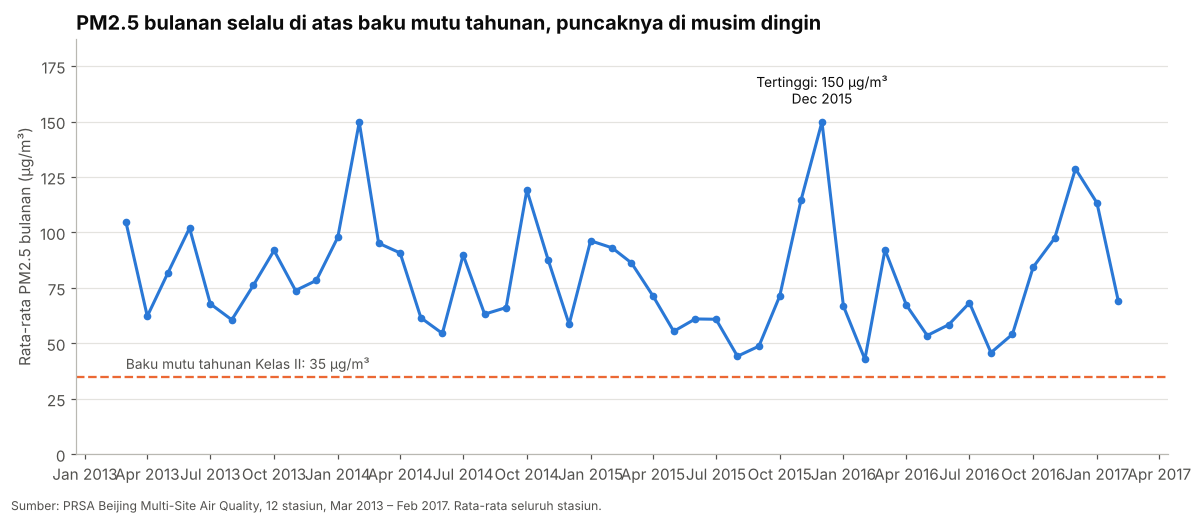

In [19]:
fig, ax = plt.subplots(figsize=(11, 4.6))
x = bulanan.index.to_timestamp()
ax.plot(x, bulanan.values, color=C_BLUE, lw=2, marker='o', ms=4)
ax.axhline(35, color=C_ORANGE, ls='--', lw=1.5)
ax.text(x[0], 37, 'Baku mutu tahunan Kelas II: 35 µg/m³', color=INK2, fontsize=9, va='bottom')

i_max = bulanan.values.argmax()
ax.annotate(f"Tertinggi: {bulanan.values[i_max]:.0f} µg/m³\n{bulanan.index[i_max].strftime('%b %Y')}",
            xy=(x[i_max], bulanan.values[i_max]), xytext=(0, 12), textcoords='offset points',
            ha='center', fontsize=9, color=INK)

ax.set_ylim(0, bulanan.max() * 1.25)
ax.set_ylabel('Rata-rata PM2.5 bulanan (µg/m³)')
ax.set_title('PM2.5 bulanan selalu di atas baku mutu tahunan, puncaknya di musim dingin')
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.grid(axis='x', visible=False)
fig.text(0.01, -0.02, SUMBER + '. Rata-rata seluruh stasiun.', fontsize=8, color=INK2)
fig.tight_layout()
plt.show()

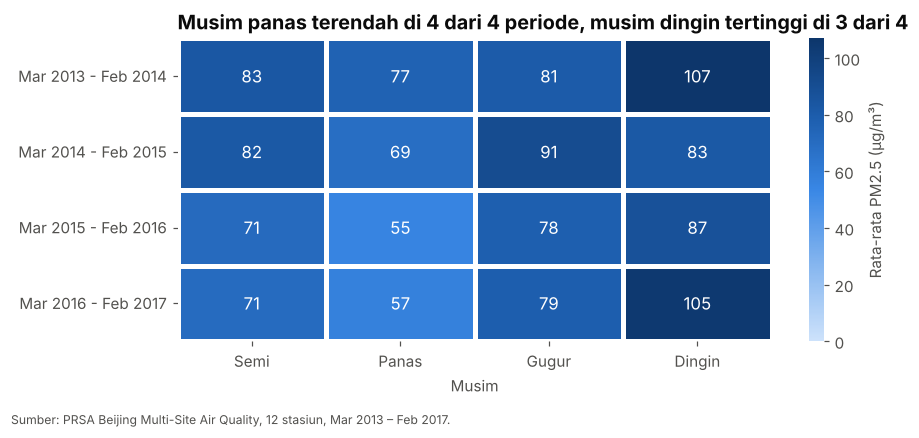

In [20]:
fig, ax = plt.subplots(figsize=(8.5, 3.8))
sns.heatmap(musim_tbl, annot=True, fmt='.0f', cmap=SEQ, vmin=0, linewidths=2, linecolor='white',
            cbar_kws={'label': 'Rata-rata PM2.5 (µg/m³)'}, annot_kws={'fontsize': 11}, ax=ax)
n_low = int((musim_tbl.idxmin(axis=1) == 'Panas').sum())
n_high = int((musim_tbl.idxmax(axis=1) == 'Dingin').sum())
ax.set_title(f'Musim panas terendah di {n_low} dari 4 periode, musim dingin tertinggi di {n_high} dari 4')
ax.set_xlabel('Musim')
ax.set_ylabel('')
ax.tick_params(axis='y', rotation=0)
ax.grid(False)
fig.text(0.01, -0.03, SUMBER + '.', fontsize=8, color=INK2)
fig.tight_layout()
plt.show()

### Pertanyaan 2: Stasiun mana yang paling sering melewati baku mutu 75 µg/m³?

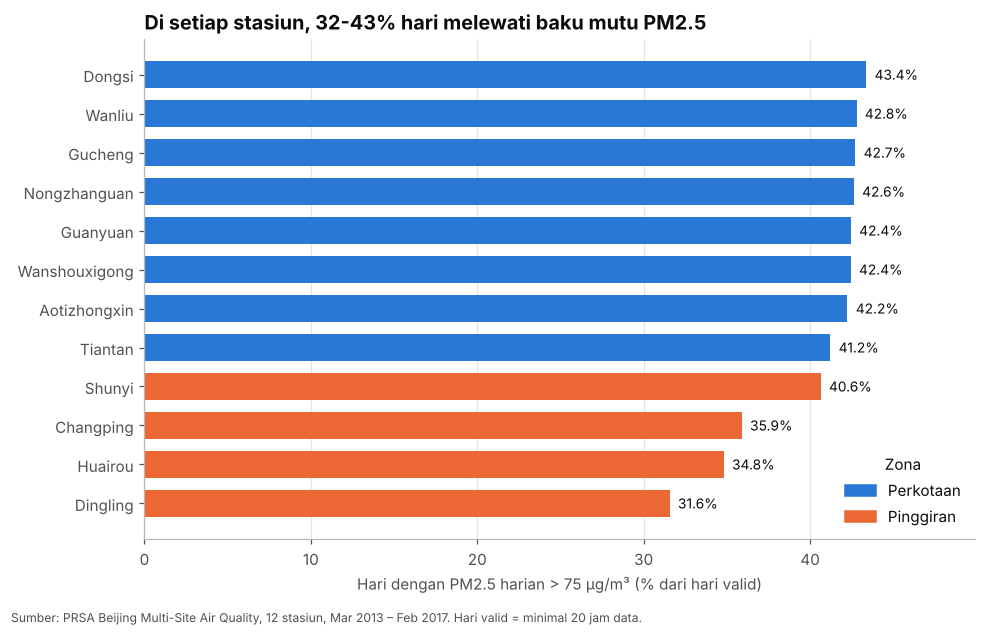

In [21]:
plot_df = stasiun_tbl.sort_values('persen')
colors = plot_df['zona'].map({'Perkotaan': C_BLUE, 'Pinggiran': C_ORANGE})

fig, ax = plt.subplots(figsize=(9, 5.6))
bars = ax.barh(plot_df['station'], plot_df['persen'], color=colors, height=0.68)
for b, v in zip(bars, plot_df['persen']):
    ax.text(v + 0.5, b.get_y() + b.get_height() / 2, f'{v:.1f}%', va='center', fontsize=9, color=INK)

ax.set_xlim(0, plot_df['persen'].max() * 1.15)
ax.set_xlabel('Hari dengan PM2.5 harian > 75 µg/m³ (% dari hari valid)')
ax.set_title(f"Di setiap stasiun, {plot_df['persen'].min():.0f}-{plot_df['persen'].max():.0f}% hari melewati baku mutu PM2.5")
ax.grid(axis='y', visible=False)
ax.legend(handles=[Patch(color=C_BLUE, label='Perkotaan'), Patch(color=C_ORANGE, label='Pinggiran')],
          loc='lower right', title='Zona')
fig.text(0.01, -0.02, SUMBER + '. Hari valid = minimal 20 jam data.', fontsize=8, color=INK2)
fig.tight_layout()
plt.show()

### Pertanyaan 3: Pada angin seperti apa PM2.5 paling tinggi?

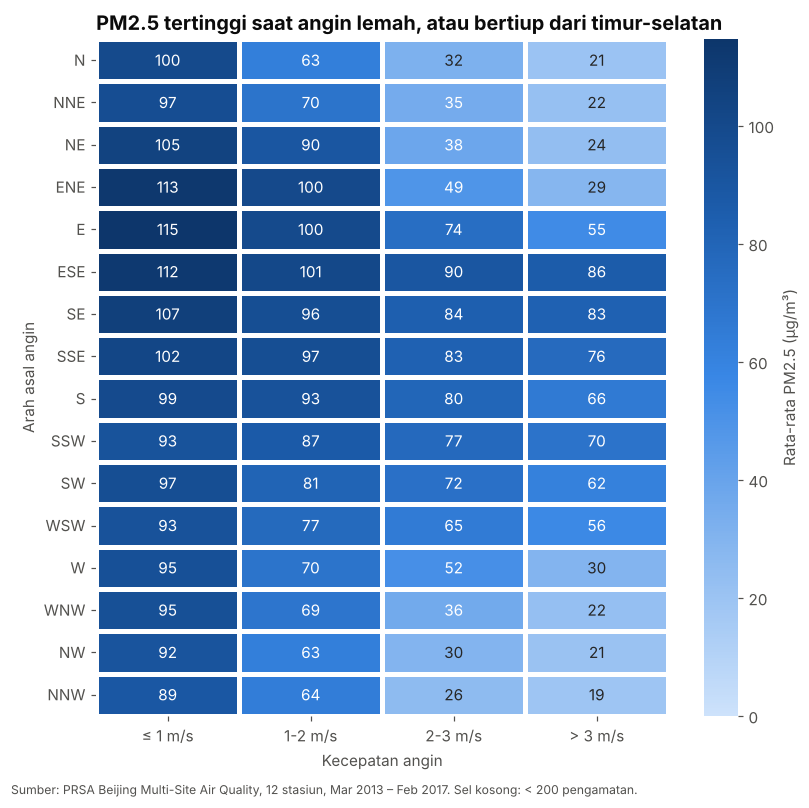

In [22]:
fig, ax = plt.subplots(figsize=(7.5, 7.2))
sns.heatmap(wind_matrix, mask=(wind_counts < MIN_N), annot=True, fmt='.0f', cmap=SEQ, vmin=0,
            linewidths=2, linecolor='white', cbar_kws={'label': 'Rata-rata PM2.5 (µg/m³)'},
            annot_kws={'fontsize': 10}, ax=ax)
ax.set_title('PM2.5 tertinggi saat angin lemah, atau bertiup dari timur-selatan')
ax.set_xlabel('Kecepatan angin')
ax.set_ylabel('Arah asal angin')
ax.tick_params(axis='y', rotation=0)
ax.grid(False)
fig.text(0.01, -0.01, SUMBER + f'. Sel kosong: < {MIN_N} pengamatan.', fontsize=8, color=INK2)
fig.tight_layout()
plt.show()

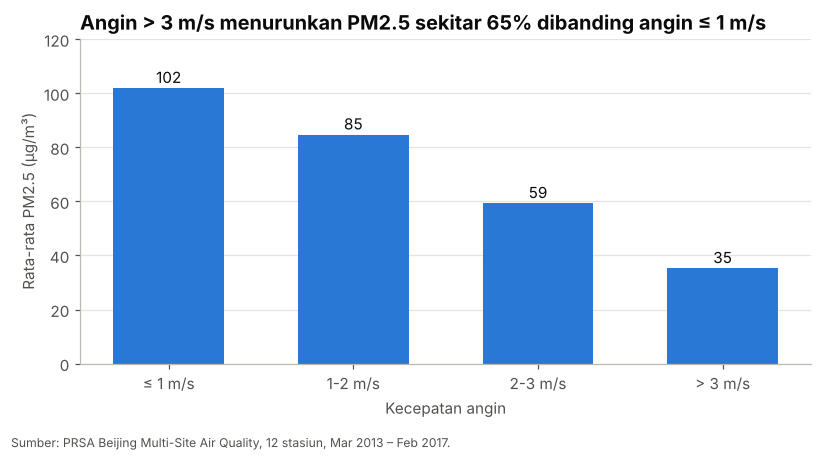

In [23]:
fig, ax = plt.subplots(figsize=(7.5, 4))
bars = ax.bar(wind_speed.index.astype(str), wind_speed['rata_rata'], color=C_BLUE, width=0.6)
for b, v in zip(bars, wind_speed['rata_rata']):
    ax.text(b.get_x() + b.get_width() / 2, v + 2, f'{v:.0f}', ha='center', fontsize=10, color=INK)
ax.set_ylim(0, wind_speed['rata_rata'].max() * 1.18)
ax.set_xlabel('Kecepatan angin')
ax.set_ylabel('Rata-rata PM2.5 (µg/m³)')
ax.set_title(f'Angin > 3 m/s menurunkan PM2.5 sekitar {turun:.0f}% dibanding angin ≤ 1 m/s')
ax.grid(axis='x', visible=False)
fig.text(0.01, -0.03, SUMBER + '.', fontsize=8, color=INK2)
fig.tight_layout()
plt.show()

**Insight:**
- **Pertanyaan 1:** PM2.5 bulanan tidak pernah turun di bawah baku mutu tahunan (terendah 42,8 µg/m³, Feb 2016) dan puncaknya terjadi pada musim dingin, terutama Desember 2015 (149,8). Heatmap menunjukkan musim panas selalu terendah, dan musim dingin tertinggi di 3 dari 4 periode.
- **Pertanyaan 2:** Di setiap stasiun, sekitar sepertiga hingga 43% hari melewati 75 µg/m³. Stasiun perkotaan hampir seragam, sedangkan pinggiran lebih bervariasi (Dingling terbaik).
- **Pertanyaan 3:** Angin lemah menaikkan PM2.5 dari semua arah (89–115 µg/m³ pada ≤ 1 m/s). Pada angin kuat (> 3 m/s) perbedaan arah terlihat jelas: dari N/NNE/NW/NNW/WNW hanya 19–22 µg/m³, sedangkan dari ESE/SE/SSE masih 76–86 µg/m³, indikasi bahwa udara dari sektor timur–selatan membawa polutan.
- Musim dan angin belum dipisahkan satu sama lain (keduanya bisa saling berkaitan), jadi pengaruh keduanya tidak boleh dibaca sebagai efek independen.

## Analisis Lanjutan: Binning kategori kualitas udara PM2.5 dan Manual Grouping zona

**Tujuan:** angka rata-rata dan persentase hari melewati ambang belum menunjukkan *seberapa parah* hari-hari tercemar tersebut. Pada bagian ini dilakukan dua teknik tanpa algoritma machine learning:

1. **Binning** — rata-rata PM2.5 harian dikelompokkan dengan `pd.cut` ke dalam 6 kategori mengacu pada titik batas indeks kualitas udara PM2.5 24 jam di China (HJ 633-2012): ≤ 35, 35–75, 75–115, 115–150, 150–250, > 250 µg/m³. Kategori ini hanya berdasarkan PM2.5, bukan AQI gabungan seluruh polutan.
2. **Manual grouping** — stasiun dikelompokkan menjadi *Perkotaan* dan *Pinggiran* berdasarkan lokasi administratif (lihat bagian Cleaning), lalu distribusi kategori dibandingkan antar zona.

In [24]:
AQI_BINS = [-np.inf, 35, 75, 115, 150, 250, np.inf]
AQI_LABELS = ['Sangat baik (≤ 35)', 'Baik (35-75)', 'Tercemar ringan (75-115)',
              'Tercemar sedang (115-150)', 'Tercemar berat (150-250)', 'Sangat berat (> 250)']
daily['kategori'] = pd.cut(daily['pm25_harian'], bins=AQI_BINS, labels=AQI_LABELS)

kat_pct = (pd.crosstab(daily['zona'], daily['kategori'], normalize='index') * 100)
display(kat_pct.round(1))

berat = (daily['pm25_harian'] > 150).groupby(daily['zona']).mean() * 100
print('Persentase hari dengan PM2.5 harian > 150 µg/m³ (tercemar berat atau lebih):')
print(berat.round(1).to_string())

kategori,Sangat baik (≤ 35),Baik (35-75),Tercemar ringan (75-115),Tercemar sedang (115-150),Tercemar berat (150-250),Sangat berat (> 250)
zona,,,,,,
Perkotaan,26.80,30.80,18.90,10.10,9.60,4.00
Pinggiran,35.30,29.00,16.90,8.20,8.60,2.10


Persentase hari dengan PM2.5 harian > 150 µg/m³ (tercemar berat atau lebih):
zona
Perkotaan   13.50
Pinggiran   10.70


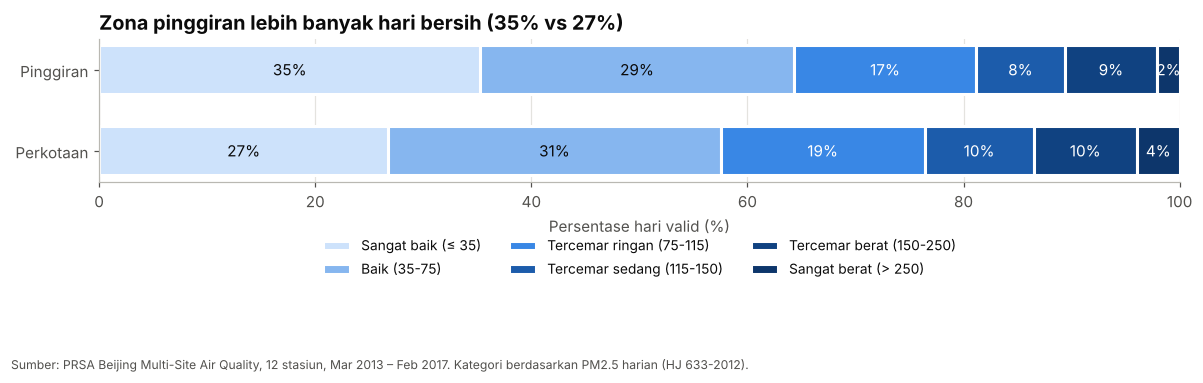

In [25]:
ramp = ['#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#104281', '#0d366b']   # satu warna, makin gelap = makin parah
fig, ax = plt.subplots(figsize=(11, 3.1))
left = pd.Series(0.0, index=kat_pct.index)
for lab, col in zip(AQI_LABELS, ramp):
    ax.barh(kat_pct.index, kat_pct[lab], left=left, color=col, edgecolor='white', linewidth=2,
            height=0.6, label=lab)
    for zona, v, l in zip(kat_pct.index, kat_pct[lab], left):
        if v >= 1.5:
            ax.text(l + v / 2, zona, f'{v:.0f}%', ha='center', va='center', fontsize=10,
                    color=INK if col in ramp[:2] else 'white')
    left = left + kat_pct[lab]

ax.set_xlim(0, 100)
ax.set_xlabel('Persentase hari valid (%)')
ax.set_title(f"Zona pinggiran lebih banyak hari bersih ({kat_pct.loc['Pinggiran', AQI_LABELS[0]]:.0f}% vs {kat_pct.loc['Perkotaan', AQI_LABELS[0]]:.0f}%)")
ax.grid(axis='y', visible=False)
ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.30), fontsize=9)
fig.text(0.01, -0.10, SUMBER + '. Kategori berdasarkan PM2.5 harian (HJ 633-2012).', fontsize=8, color=INK2)
fig.tight_layout()
plt.show()

**Insight:**
- **Perkotaan:** 26,8% hari sangat baik, 30,8% baik, 18,9% tercemar ringan, 10,1% sedang, 9,6% berat, 4,0% sangat berat. **Pinggiran:** 35,3% / 29,0% / 16,9% / 8,2% / 8,6% / 2,1%.
- Hari tercemar berat atau lebih (> 150 µg/m³) mencapai **13,5%** di perkotaan dan **10,7%** di pinggiran; sekitar 1 dari 7 hari di kota tergolong tercemar berat atau lebih.
- Zona pinggiran memiliki lebih banyak hari bersih (35% vs 27%), tetapi perbedaan pada hari-hari paling parah relatif kecil, selaras dengan temuan bahwa pencemaran bersifat regional.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Rata-rata PM2.5 per periode 12 bulan adalah 86,8; 81,4; 72,9; dan 78,0 µg/m³ (periode Mar 2013 – Feb 2017), selalu 2,1–2,5 kali baku mutu tahunan 35 µg/m³ dan sempat naik 6,9% pada periode terakhir setelah turun dua periode berturut-turut. Musim dingin tertinggi (95,5 µg/m³) dan musim panas terendah (64,6 µg/m³); secara bulanan, Oktober–Maret konsisten 88–104 µg/m³ dengan puncak Desember 2015 (149,8 µg/m³).
- **Conclusion pertanyaan 2:** Persentase hari melewati 75 µg/m³ berkisar 31,6% (Dingling, terendah) hingga 43,4% (Dongsi, tertinggi). Zona perkotaan 42,5% vs pinggiran 35,7% (selisih 6,8 poin persentase), dengan delapan stasiun perkotaan nyaris seragam (41,2–43,4%) dan Shunyi (pinggiran) hampir setara kota (40,6%). Pola ini mengarah pada pencemaran yang bersifat regional, bukan masalah satu-dua stasiun.
- **Conclusion pertanyaan 3:** PM2.5 tertinggi terjadi saat angin lemah (≤ 1 m/s) dari timur (E 114,7; ENE 113,3; ESE 112,4 µg/m³). Rata-rata PM2.5 turun 65,4% (dari 101,7 menjadi 35,2 µg/m³) ketika angin > 3 m/s, namun angin kuat dari ESE/SE/SSE tetap membawa 76–86 µg/m³, sedangkan dari utara–barat laut hanya 19–22 µg/m³.
- **Catatan:** analisis ini bersifat observasional. Dataset tidak memuat sumber emisi dan pengaruh musim, angin, dan lokasi belum dipisahkan, sehingga hasilnya menunjukkan pola, bukan penyebab pasti.

**Rekomendasi Action Item:**
- **Peringatan dini berbasis cuaca:** keluarkan imbauan (kurangi aktivitas luar ruang, masker, pembatasan emisi sementara) ketika prakiraan angin ≤ 1 m/s atau angin lemah–sedang (≤ 2 m/s) dari sektor timur–tenggara, karena rata-rata PM2.5 pada kondisi tersebut 96–115 µg/m³ (±1,3–1,5× baku mutu harian 75 µg/m³). Angin > 3 m/s dari utara–barat laut dapat dijadikan indikator udara relatif bersih (≈ 20 µg/m³).
- **Perkuat program pengendalian pada Oktober–Maret:** rata-rata bulanan 88–104 µg/m³ pada bulan-bulan ini, jauh di atas April–September (53–73 µg/m³). Jadwalkan inspeksi emisi, pembatasan aktivitas berpolusi, dan kampanye kesehatan sebelum Oktober.
- **Terapkan kebijakan kota-luas dan koordinasi regional, bukan per-stasiun:** hampir semua stasiun (kecuali Dingling, Huairou, Changping) melewati ambang pada 40–43% hari, dan angin kuat dari timur–selatan tetap membawa PM2.5 tinggi. Koordinasikan pembatasan emisi dengan wilayah sekitar, dan prioritaskan zona perkotaan (13,5% hari > 150 µg/m³).
- **Perbaiki kualitas pemantauan:** gap hingga 343 jam dan sensor macet (41 jam di Dongsi) mengurangi keandalan data; tambahkan alarm otomatis untuk nilai identik berulang dan kehilangan data > 6 jam.
- **Analisis lanjutan yang disarankan:** pisahkan efek musim dan angin (mis. bandingkan kecepatan angin dalam musim yang sama) dan tambahkan data sumber emisi sebelum menetapkan kebijakan sumber tertentu.